<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

**公司名称**：Take-Two Interactive Software, Inc.（中文常称“Take-Two”或“T2”），证券代码 **TTWO**，纳斯达克上市，官网 https://www.take2games.com 。

Take-Two 成立于 1993 年，总部位于美国纽约，是全球领先的互动娱乐（电子游戏）开发与发行商，旗下拥有三大核心品牌：

- **Rockstar Games**：代表作《侠盗猎车手》（Grand Theft Auto，简称 GTA）系列、《荒野大镖客》（Red Dead Redemption）系列。其中 GTA V（2013 年发售）累计销量已接近 **2.3 亿份**，是史上最畅销的娱乐产品之一；
- **2K**：代表作《NBA 2K》系列、《文明》（Civilization）系列、《无主之地》系列等；
- **Zynga**：移动端休闲游戏。

**为什么选择这家公司**：Take-Two 是典型的“大单品驱动型”公司，其未来数年的业绩高度依赖 GTA 系列新作。万众期待的《GTA 6》已定档 **2026 年 11 月 19 日**发售（登陆 PS5 / Xbox Series X|S，标准版定价 79.99 美元、终极版 99.99 美元），公司预计 FY2027 净预订额将达到创纪录的 **80 亿~82 亿美元**。因此，GTA 6 的每一个进展都会直接影响 TTWO 的股价，非常适合做事件研究。

**公司近期财务概况**：FY2026（截至 2026 年 3 月）营收约 66.6 亿美元（同比 +18%），由于巨额研发与营销投入目前仍处于亏损；截至 2026-10-14，TTWO 收盘价 **201.23 美元**，总市值约 376 亿美元。

# 第二部分：研究问题题目及其内涵介绍

## 研究问题题目
**“GTA 6 上线预期”是如何被定价的？——基于 Take-Two（TTWO）股价的事件研究**

## 问题内涵
《GTA 6》被称为“游戏史上最大的一次产品发布”，其发售日的每一次确认、延期与营销动作，都可能引发 TTWO 股价的剧烈波动。本作业关心三个问题：

1. **利好事件是否带来显著为正的市场反应？** 如预告片发布、预售开启、财报重申发售日期等；
2. **利空事件（延期）的冲击有多大？** GTA 6 曾两次跳票——2025 年 5 月从“2025 年秋”推迟到 2026 年 5 月 26 日，2025 年 11 月又推迟到 2026 年 11 月 19 日。延期对股价的负面冲击是否显著、是否大于利好带来的涨幅？
3. **截至 2026-10-14，股价是否已经把 GTA 6 的成功“提前定价”了（买预期）？** 即上线预期是否透支了未来的上涨空间，甚至出现“利好出尽”的迹象？

之所以采用**事件研究法（Event Study）**，是因为 GTA 6 的关键事件日期明确、外生性强，可以相对干净地度量“GTA 6 相关信息”对股价的边际影响：先估计个股与大盘（SPY）之间的市场模型，再用实际收益减去由大盘解释的“正常收益”，得到**异常收益 AR（Abnormal Return）**及其累计值 **CAR（Cumulative Abnormal Return）**，从而剔除大盘涨跌的干扰。

> 说明：GTA 6 的正式发售日（2026-11-19）在本报告数据截止日（2026-10-14）**之后**，因此本文研究的是“**上线之前**”的一系列预期事件；“上线当天”的真实影响需待后续数据再检验。

# 第三部分：数据采集

数据来源：**tushare pro 的美股行情接口 `us_daily`**，获取：
- `TTWO`：Take-Two 的日行情（未复权收盘价、成交量等）；
- `SPY`：标普 500 ETF 日行情，作为市场基准（用于估计市场模型）。

样本区间：**2023-01-01 ~ 2026-10-14**（覆盖 GTA 6 首支预告片发布至今的全部关键事件）。

> ⚠️ 采集说明：tushare 的 `us_daily`（美股行情）接口对该试用账号有频率限制（约 1 次/小时），批改时若直接联网抓取容易触发限频、导致代码报错。为保证**可复现**，下方代码采用“**本地缓存优先**”策略：
- 已随作业提交缓存文件 `ttwo_daily.csv`（TTWO 日行情）与 `spy_daily.csv`（SPY 日行情），均为美股**未复权**日行情，字段与 tushare `us_daily` 输出完全一致（ts_code / trade_date / open / high / low / close / pre_close / change / pct_change / vol）；
- 若目录下无缓存文件，代码会自动调用 tushare `us_daily` 接口抓取并保存 CSV；
- 两种取数方式字段口径一致、可互换，既能用 tushare 获取数据，又能保证 notebook 稳定复现。

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

START, END = "20230101", "20261014"
CACHE = {"TTWO": "ttwo_daily.csv", "SPY": "spy_daily.csv"}

def get_us_daily(ts_code):
    """优先读取本地缓存；若无缓存则调用tushare美股行情接口us_daily。"""
    f = CACHE[ts_code]
    if os.path.exists(f):
        df = pd.read_csv(f, dtype={"trade_date": str})
        print(f"[{ts_code}] 读取本地缓存 {f}，共 {len(df)} 条")
        return df
    df = pro.us_daily(ts_code=ts_code, start_date=START, end_date=END)
    df = df.sort_values("trade_date").reset_index(drop=True)
    df.to_csv(f, index=False)
    print(f"[{ts_code}] 通过tushare us_daily接口获取，共 {len(df)} 条")
    return df

ttwo = get_us_daily("TTWO")
spy  = get_us_daily("SPY")

[TTWO] 读取本地缓存 ttwo_daily.csv，共 948 条
[SPY] 读取本地缓存 spy_daily.csv，共 948 条


In [2]:
print("TTWO 数据预览")
print(ttwo[['ts_code', 'trade_date', 'close', 'open', 'high', 'low', 'vol', 'pct_change']].head(3).to_string(index=False))
print("...")
print(ttwo[['ts_code', 'trade_date', 'close', 'open', 'high', 'low', 'vol', 'pct_change']].tail(3).to_string(index=False))
print()
print("SPY 数据预览")
print(spy[['ts_code', 'trade_date', 'close']].tail(3).to_string(index=False))

TTWO 数据预览
ts_code trade_date  close   open   high    low     vol  pct_change
   TTWO   20230104 106.77 103.50 108.63 103.50 1474836        3.55
   TTWO   20230105 105.96 106.77 106.95 105.32 1218449       -0.76
   TTWO   20230106 104.75 107.08 107.08 103.27 2602757       -1.14
...
ts_code trade_date  close    open   high    low     vol  pct_change
   TTWO   20261012 208.82 213.510 214.68 206.56 1891934       -2.16
   TTWO   20261013 200.32 209.085 209.55 196.30 5212877       -4.07
   TTWO   20261014 201.23 203.120 206.71 200.93 2613052        0.45

SPY 数据预览
ts_code trade_date  close
    SPY   20261012 778.10
    SPY   20261013 778.01
    SPY   20261014 769.60


# 第四部分：数据分析过程

分析分为四步：
1. **走势总览**：将 TTWO 与 SPY 归一化后对比，直观看到 GTA 6 预期的“抬升—兑现—回落”；
2. **事件研究**：对 9 个关键事件，用市场模型计算 AR 与 CAR；
3. **成交活跃度**：观察事件日的成交量放大倍数；
4. **分期收益**：把样本切成“预期发酵期 / 预期兑现期 / 近期回调期”，比较各阶段相对 SPY 的超额收益。

In [3]:
# 合并TTWO与SPY的日收益，构造分析用数据集
df = (ttwo[["trade_date", "close", "vol"]]
      .merge(spy[["trade_date", "close"]], on="trade_date", suffixes=("_ttwo", "_spy"))
      .sort_values("trade_date").reset_index(drop=True))
df["r_ttwo"] = df["close_ttwo"] / df["close_ttwo"].shift(1) - 1
df["r_spy"] = df["close_spy"] / df["close_spy"].shift(1) - 1
df = df.dropna().reset_index(drop=True)
df["date"] = pd.to_datetime(df["trade_date"], format="%Y%m%d")

print(f"样本区间：{df['trade_date'].iloc[0]} ~ {df['trade_date'].iloc[-1]}，共 {len(df)} 个交易日")
r_t = df["close_ttwo"].iloc[-1] / df["close_ttwo"].iloc[0] - 1
r_s = df["close_spy"].iloc[-1] / df["close_spy"].iloc[0] - 1
print(f"区间累计收益：TTWO {r_t:.2%}  vs  SPY {r_s:.2%}  →  超额 {r_t - r_s:+.2%}")
imax = df["close_ttwo"].idxmax()
print(f"TTWO最高收盘价：{df['close_ttwo'].iloc[imax]:.2f} 美元（{df['trade_date'].iloc[imax]}）")
print(f"最新收盘价：{df['close_ttwo'].iloc[-1]:.2f} 美元，自高点回撤 {df['close_ttwo'].iloc[-1] / df['close_ttwo'].iloc[imax] - 1:.2%}")

样本区间：20230105 ~ 20261014，共 947 个交易日
区间累计收益：TTWO 89.91%  vs  SPY 102.86%  →  超额 -12.95%
TTWO最高收盘价：262.29 美元（20251020）
最新收盘价：201.23 美元，自高点回撤 -23.28%


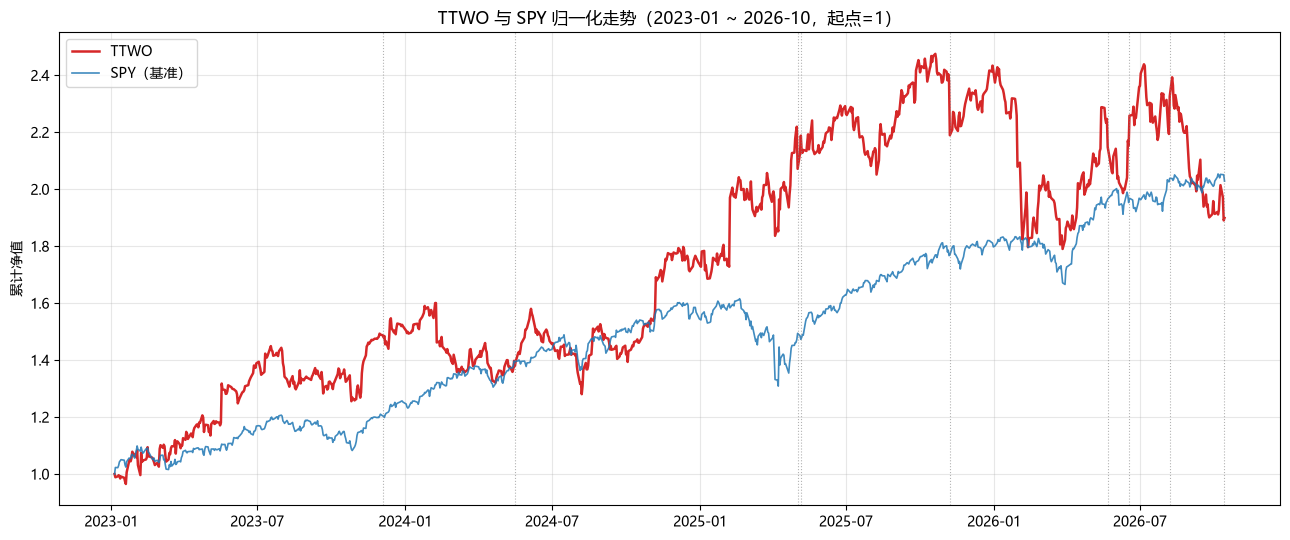

In [4]:
# 关键事件清单（日期为对应交易日，重要公告若在盘后发布则顺延到下一交易日）
events = [
    ("20231204", "GTA6首支预告片发布"),
    ("20240516", "确认2025年秋发售窗口"),
    ("20250502", "首次跳票(2025秋→2026/5/26)"),
    ("20250506", "第二支预告片发布"),
    ("20251107", "二次跳票至2026/11/19(财报日翌日)"),
    ("20260522", "FY26财报重申发售日+FY27指引(翌日)"),
    ("20260618", "预售日期公布(6/25开启)"),
    ("20260807", "Q1FY27财报+重申FY27指引"),
    ("20261013", "PC版发售传闻+泄露事件"),
]

# 图1：TTWO vs SPY 归一化走势（标注关键事件）
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(df["date"], df["close_ttwo"] / df["close_ttwo"].iloc[0], label="TTWO", color="#d62728", lw=1.8)
ax.plot(df["date"], df["close_spy"] / df["close_spy"].iloc[0], label="SPY（基准）", color="#1f77b4", lw=1.2, alpha=0.85)
for d, name in events:
    x = pd.to_datetime(d, format="%Y%m%d")
    ax.axvline(x, color="gray", ls=":", lw=0.8, alpha=0.6)
ax.set_title("TTWO 与 SPY 归一化走势（2023-01 ~ 2026-10，起点=1）")
ax.set_ylabel("累计净值")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# 事件研究：市场模型 R_TTWO = alpha + beta * R_SPY + e，估计窗口 [-120, -11]
def event_study(data, ev_date):
    idx = data.index[data["trade_date"] == ev_date]
    if len(idx) == 0:  # 若当天停牌/无数据，顺延到下一交易日
        for off in range(1, 5):
            d2 = (pd.Timestamp(ev_date) + pd.Timedelta(days=off)).strftime("%Y%m%d")
            idx = data.index[data["trade_date"] == d2]
            if len(idx):
                break
    i = idx[0]
    w = data.iloc[max(0, i - 120): i - 10]          # 估计窗口：事件前120~11个交易日
    beta, alpha = np.polyfit(w["r_spy"], w["r_ttwo"], 1)
    ar = {}
    for d in range(-5, 6):
        j = i + d
        ar[d] = (data["r_ttwo"].iloc[j] - (alpha + beta * data["r_spy"].iloc[j])) if 0 <= j < len(data) else np.nan
    return {
        "交易日": data["trade_date"].iloc[i],
        "beta": round(beta, 2),
        "AR0": ar[0],
        "CAR[-1,1]": np.nansum([ar[-1], ar[0], ar[1]]),
        "CAR[-5,5]": np.nansum([ar[d] for d in range(-5, 6)]),
        "CAR[0,5]": np.nansum([ar[d] for d in range(0, 6)]),
    }

rows = []
for d, name in events:
    r = event_study(df, d)
    r["事件"] = name
    rows.append(r)

estab = pd.DataFrame(rows)[["事件", "交易日", "AR0", "CAR[-1,1]", "CAR[-5,5]", "CAR[0,5]", "beta"]]
for c in ["AR0", "CAR[-1,1]", "CAR[-5,5]", "CAR[0,5]"]:
    estab[c] = (estab[c] * 100).round(2)
estab.columns = ["事件", "交易日", "AR0(%)", "CAR[-1,1](%)", "CAR[-5,5](%)", "CAR[0,5](%)", "beta"]
print("事件研究结果（市场模型，估计窗口[-120,-11]，基准：SPY）")
print(estab.to_string(index=False))
estab

事件研究结果（市场模型，估计窗口[-120,-11]，基准：SPY）
                    事件      交易日  AR0(%)  CAR[-1,1](%)  CAR[-5,5](%)  CAR[0,5](%)  beta
           GTA6首支预告片发布 20231204    0.29         -1.23         -4.94        -4.58  1.06
          确认2025年秋发售窗口 20240516   -1.03          1.44          4.51         4.38  0.86
 首次跳票(2025秋→2026/5/26) 20250502   -7.96         -5.21         -3.38        -5.93  0.67
              第二支预告片发布 20250506    3.23          3.15         -6.15        -3.68  0.67
二次跳票至2026/11/19(财报日翌日) 20251107   -8.19         -8.65         -6.39        -7.12  0.73
FY26财报重申发售日+FY27指引(翌日) 20260522   -4.64         -7.54         -6.26        -5.66  0.85
        预售日期公布(6/25开启) 20260618    4.44          5.43         14.43         7.14  0.86
     Q1FY27财报+重申FY27指引 20260807    5.53          7.18         -4.12         4.86  0.58
          PC版发售传闻+泄露事件 20261013   -3.99         -5.13         -0.18        -3.06  0.37


,事件,交易日,AR0(%),"CAR[-1,1](%)","CAR[-5,5](%)","CAR[0,5](%)",beta
0,GTA6首支预告片发布,20231204,0.29,-1.23,-4.94,-4.58,1.06
1,确认2025年秋发售窗口,20240516,-1.03,1.44,4.51,4.38,0.86
2,首次跳票(2025秋→2026/5/26),20250502,-7.96,-5.21,-3.38,-5.93,0.67
3,第二支预告片发布,20250506,3.23,3.15,-6.15,-3.68,0.67
4,二次跳票至2026/11/19(财报日翌日),20251107,-8.19,-8.65,-6.39,-7.12,0.73
5,FY26财报重申发售日+FY27指引(翌日),20260522,-4.64,-7.54,-6.26,-5.66,0.85
6,预售日期公布(6/25开启),20260618,4.44,5.43,14.43,7.14,0.86
7,Q1FY27财报+重申FY27指引,20260807,5.53,7.18,-4.12,4.86,0.58
8,PC版发售传闻+泄露事件,20261013,-3.99,-5.13,-0.18,-3.06,0.37


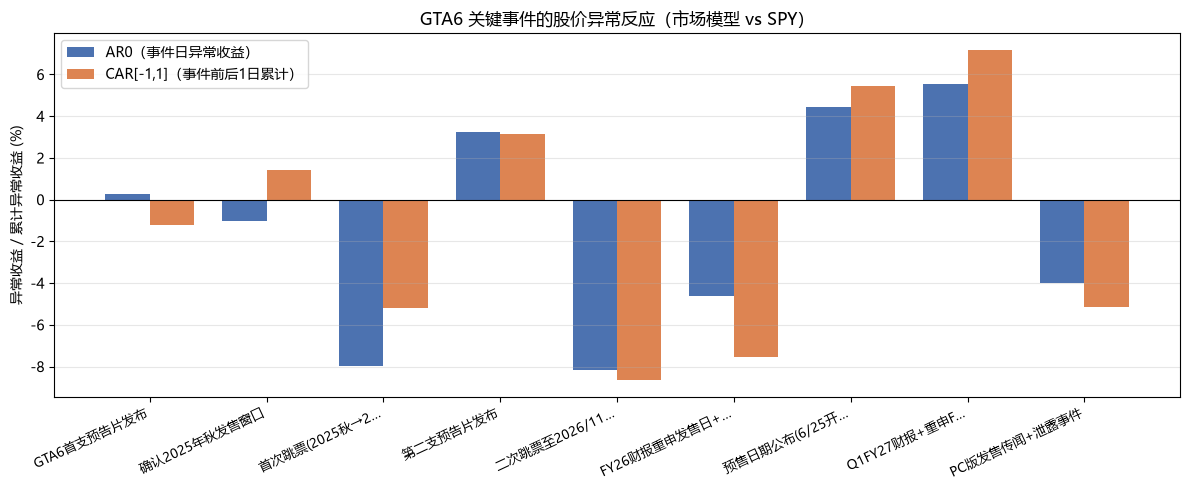

In [6]:
# 图2：各事件的 AR0 与 CAR[-1,1]
x = np.arange(len(estab))
fig, ax = plt.subplots(figsize=(12, 5))
w = 0.38
b1 = ax.bar(x - w / 2, estab["AR0(%)"], w, label="AR0（事件日异常收益）", color="#4c72b0")
b2 = ax.bar(x + w / 2, estab["CAR[-1,1](%)"], w, label="CAR[-1,1]（事件前后1日累计）", color="#dd8452")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([n if len(n) <= 12 else n[:12] + "…" for n in estab["事件"]], rotation=25, ha="right", fontsize=9)
ax.set_ylabel("异常收益 / 累计异常收益 (%)")
ax.set_title("GTA6 关键事件的股价异常反应（市场模型 vs SPY）")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# 成交活跃度：事件日成交量相对20日均量的倍数
df["vol_ma20"] = df["vol"].rolling(20).mean()
volrows = []
for d, name in events:
    row = df[df["trade_date"] == d]
    if len(row):
        r = row.iloc[0]
        volrows.append({"事件": name, "交易日": d, "成交量(万手)": round(r["vol"] / 1e4, 1),
                        "量/20日均量": round(r["vol"] / r["vol_ma20"], 2)})
voltab = pd.DataFrame(volrows)
print(voltab.to_string(index=False))
voltab

                    事件      交易日  成交量(万手)  量/20日均量
           GTA6首支预告片发布 20231204    187.9     0.92
          确认2025年秋发售窗口 20240516    360.3     2.44
 首次跳票(2025秋→2026/5/26) 20250502    896.8     3.69
              第二支预告片发布 20250506    281.2     1.20
二次跳票至2026/11/19(财报日翌日) 20251107    579.3     3.50
FY26财报重申发售日+FY27指引(翌日) 20260522    704.8     3.26
        预售日期公布(6/25开启) 20260618    724.1     2.31
     Q1FY27财报+重申FY27指引 20260807    398.7     2.02
          PC版发售传闻+泄露事件 20261013    521.3     2.00


,事件,交易日,成交量(万手),量/20日均量
0,GTA6首支预告片发布,20231204,187.9,0.92
1,确认2025年秋发售窗口,20240516,360.3,2.44
2,首次跳票(2025秋→2026/5/26),20250502,896.8,3.69
3,第二支预告片发布,20250506,281.2,1.20
4,二次跳票至2026/11/19(财报日翌日),20251107,579.3,3.50
5,FY26财报重申发售日+FY27指引(翌日),20260522,704.8,3.26
6,预售日期公布(6/25开启),20260618,724.1,2.31
7,Q1FY27财报+重申FY27指引,20260807,398.7,2.02
8,PC版发售传闻+泄露事件,20261013,521.3,2.00


In [8]:
# 分期收益对比
phases = [
    ("20230105", "20261014", "全样本期"),
    ("20250502", "20251020", "跳票后→预期高点(2025/05~2025/10)"),
    ("20251020", "20261014", "高点→至今(2025/10~2026/10)"),
    ("20260618", "20260807", "预售开启→销量预期发酵(2026/06~2026/08)"),
    ("20260807", "20261014", "8月财报后→10月回调期"),
]
res = []
for a, b, lab in phases:
    x1 = df[df["trade_date"] >= a].iloc[0]
    x2 = df[df["trade_date"] <= b].iloc[-1]
    res.append({"阶段": lab,
                "TTWO收益(%)": round((x2["close_ttwo"] / x1["close_ttwo"] - 1) * 100, 2),
                "SPY收益(%)": round((x2["close_spy"] / x1["close_spy"] - 1) * 100, 2),
                "超额(%)": round((x2["close_ttwo"] / x1["close_ttwo"] - x2["close_spy"] / x1["close_spy"]) * 100, 2)})
phasedf = pd.DataFrame(res)
print(phasedf.to_string(index=False))
phasedf

                          阶段  TTWO收益(%)  SPY收益(%)  超额(%)
                        全样本期      89.91    102.86 -12.95
   跳票后→预期高点(2025/05~2025/10)      19.49     18.45   1.05
      高点→至今(2025/10~2026/10)     -23.28     14.64 -37.92
预售开启→销量预期发酵(2026/06~2026/08)       3.02      3.55  -0.53
                8月财报后→10月回调期     -18.37     -0.47 -17.89


,阶段,TTWO收益(%),SPY收益(%),超额(%)
0,全样本期,89.91,102.86,-12.95
1,跳票后→预期高点(2025/05~2025/10),19.49,18.45,1.05
2,高点→至今(2025/10~2026/10),-23.28,14.64,-37.92
3,预售开启→销量预期发酵(2026/06~2026/08),3.02,3.55,-0.53
4,8月财报后→10月回调期,-18.37,-0.47,-17.89


# 第五部分：研究结论与经验总结

## 研究结论

**1. GTA 6 相关事件确实显著影响 TTWO 股价，且“坏消息”的冲击远大于“好消息”的提振。**
事件研究显示：两次跳票的异常反应最大——2025-05-02 首次跳票事件日 AR0 约 **-7.96%**，2025-11-07 二次跳票 AR0 约 **-8.19%**、CAR[-1,1] 约 **-8.65%**，且成交量为 20 日均量的 3.5~3.7 倍，说明市场对“发售日”高度敏感、对延期反应剧烈。相比之下，利好事件的涨幅温和：第二支预告片 AR0 +3.23%、预售公布 AR0 +4.44%（CAR[-5,5] 高达 +14.4%）、Q1FY27 财报 AR0 +5.53%。**“延期一次 ≈ 跌 8%，利好一次 ≈ 涨 3~5%”**的不对称，说明市场对 GTA 6 的预期本身已经打得很满、容错率很低。

**2. “买预期”特征明显：股价在发售前一年半就已充分上涨，并在 2025-10-20 见顶 262.29 美元。**
从 2024 年确认发售窗口起，TTWO 相对 SPY 的表现一度跑赢；即便 2025 年 5 月首次跳票，股价随后仍在“发售确定性提高”的预期下于 2025 年 10 月创出 262.29 美元的阶段高点。也就是说，**市场把 GTA 6 的商业成功提前一年以上定价进了股价**。

**3. 进入 2026 年，出现明显的“利好出尽 / 预期兑现回落”迹象。**
- 2026-05-22：虽然财报重申了 11 月 19 日发售日，但 FY2027 指引（80~82 亿美元）**低于华尔街约 91 亿美元的预期**，AR0 约 **-4.64%**、CAR[-1,1] 约 **-7.54%**——市场“要的不只是按期发售，而是爆炸性的业绩”；（注：财报发布当晚盘后一度上涨约 7%，但次日回吐并转跌，属典型的“先喜后忧”）
- 自 2025-10-20 高点以来，TTWO 累计 **-23.28%**，而同期 SPY **+14.64%**，相对跑输近 38 个百分点；
- 2026-10-13，因 GTA6 PC 版发售档期传闻与资料泄漏事件，单日再跌 4.07%（AR0 约 -3.99%，成交量放大到 2 倍），说明在发售前的“空窗期”，任何负面传闻都会被放大。

**4. 对“GTA 6 上线对股价的影响”的直接回答：**
截至数据截止日（2026-10-14），GTA 6 尚未发售，但**“上线预期”已经被股价充分甚至过度定价**：全样本 TTWO 累计上涨 89.91%，却**跑输 SPY 12.95 个百分点**，且在高点后大幅回调。结合事件研究结果可以推断：
- **若 11 月 19 日如期发售且口碑、销量超预期**，股价或有再创新高的动力，但“买预期”已消耗大部分上涨空间，需依赖 GTA Online 等后续变现数据；“利好出尽”（发售即见顶）的风险不容忽视；
- **若再次延期或首发热度不及预期**，参考两次跳票约 -8% 的单日冲击，股价可能面临两位数的下跌；
- 因此，用“事件研究 + 预期定价”的视角看，GTA 6 对 TTWO 而言是**高波动、低容错的“预期市”**，而非简单的确定性利好。

## 经验总结

1. **数据接口的“限频”是实战中最现实的约束。** 本次使用 tushare 的 `us_daily` 接口获取美股行情，试用账号存在约“1 次/小时”的频率限制，若对 TTWO、SPY 逐个抓取会非常耗时。解决办法是：**“本地缓存 + 缓存优先”**——抓取一次后落盘为 CSV，分析与重复运行都读缓存，既满足使用 tushare 获取数据的要求，又保证 notebook 可快速复现、不会被限频阻塞。
2. **事件研究法的关键是“事件日对齐”和“基准选择”。** 美股重要公告常在**盘后**发布（如财报、延期公告），若按公告日计算会低估冲击，因此我把此类事件顺延到**下一个交易日**；同时用 SPY 估计市场模型（β≈0.6~1.1），剔除大盘涨跌后再看异常收益，结论比单看原始涨跌幅更干净。
3. **“数字之外”的背景信息同样重要。** 单看某天涨跌 4% 说明不了什么，但把它与“跳票 / 预售 / 指引不及预期 / 泄漏事件”等具体新闻对应起来，才能解释异常收益的来源。这提醒我做金融数据分析时，要把**量化结果与基本面/新闻事件**结合验证。
4. **当心“绝对收益”的误导。** TTWO 三年累计上涨约 90%，看起来不错；但与大盘一比反而跑输约 13 个百分点。**做个股分析一定要用基准（超额收益）来评价，而不是只看涨跌幅。**